# High Pass Filter Using the Spectral Inversion Technique

We can also create a high pass filter by using as reference a low pass filter and another technique called **Spectral Inversion**. For this notebook we will use the *Windowed-Sinc Filters* Notebook results, which are pickled in an serialized object called `save_data.pickle`.

<font color="blue">Note: In order to run this Jupyter Notebook you must create a file named `aux_functions.py` inside the folder containing this Notebook with the following functions `get_fourier`, `shifted_sinc_function`,  `hamming_window` and `blackman_window` which were developed previously.</font> 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pickle

from aux_functions import get_fourier
from aux_plots import plot_frequency_response

## Load the data and the Low-Pass Filter Coefficients
We load the low pass data from the *Windowed-Sinc Filters* Notebook

In [2]:
with open('save_data.pickle', 'rb') as f:
    data = pickle.load(f)
    
ecg = np.array(data['ecg'])
low_pass = np.array(data['low_pass'])
low_pass = low_pass/np.sum(low_pass)
fft_low_pass = np.array(data['fft_low_pass'])

## Create a High-Pass Filter
To generate the high pass filter, we use the **Sprectral Inversion** methond, which consist of multiplying the low pass filter response $h_{lp}[n]$ with $-1$ and then add $1$ to the center value. Therefore the high pass filter response is given by:
$$h_{hp}[n] = \delta[n] -h_{lp}[n]$$

Implement a high-pass filter function called `spectral_inversion` wich takes as input an array of low-pass filter coefficients `h_lp` and returns an array of high-pass filter coefficient using the equation described before.

In [3]:
def spectral_inversion(h_lp):
    """
    Function that performs the spectral inversion of a low pass filter with
    coefficients h_lp and returns the high pass coefficients h_hp.
  
    Parameters: 
    h_lp (array): Array of numbers representing the low pass filter coefficients.
  
    Returns: 
    numpy array: Array of numbers representing the high pass filter coefficients.
    """
    ### BEGIN SOLUTION
    h_hp = -h_lp
    center = int(len(h_hp)/2)
    h_hp[center] = h_hp[center] + 1
    return h_hp
    ### END SOLUTION

In [4]:
# Use the spectral_inversion function on low pass filter to obtain a high pass filter.
# The coefficients of the low pass filter are stored in the low_pass variable.
# Store the result in a variable named high_pass.
### BEGIN SOLUTION
high_pass = spectral_inversion(low_pass)
### END SOLUTION

In [5]:
with open('high_pass_spectral.pkl', 'rb') as file:
    high_pass_pkl = pickle.load(file)
    

assert np.allclose(high_pass_pkl, high_pass, atol=0.01)

In [6]:
# Find the Fourier Transform for the low pass filter and assign:
# The magnitude to dft_low_pass_magnitude
# The normalized frequency to dft_low_pass_freq
### BEGIN SOLUTION
dft_low_pass_magnitude, dft_low_pass_freq = get_fourier(low_pass)
### END SOLUTION

# Find the Fourier Transform for the high pass filter and assign:
# The magnitude to dft_high_pass_magnitude
# The normalized frequency to dft_high_pass_freq
### BEGIN SOLUTION
dft_high_pass_magnitude, dft_high_pass_freq = get_fourier(high_pass)
### END SOLUTION

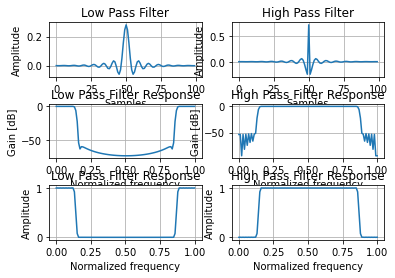

In [7]:
with open('high_pass_spectral_dft.pkl', 'rb') as file:
    dft_low_pass_magnitude_pkl, dft_low_pass_freq_pkl, \
    dft_high_pass_magnitude_pkl, dft_high_pass_freq_pkl = pickle.load(file)
    
    
assert np.allclose(dft_low_pass_magnitude_pkl, dft_low_pass_magnitude, atol=0.01)
assert np.allclose(dft_low_pass_freq_pkl, dft_low_pass_freq, atol=0.01)
assert np.allclose(dft_high_pass_magnitude_pkl, dft_high_pass_magnitude, atol=0.01)
assert np.allclose(dft_high_pass_freq_pkl, dft_high_pass_freq, atol=0.01)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(3,2,1)
plt.plot(low_pass)
#plt.stem(low_pass, markerfmt='.', use_line_collection=True)
plt.title('Low Pass Filter')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(3,2,2)
plt.plot(high_pass)
#plt.stem(high_pass, markerfmt='.', use_line_collection=True)
plt.title('High Pass Filter')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(3,2,3)
dft_low_pass_magnitude_reshape = np.copy(dft_low_pass_magnitude)
plot_frequency_response(dft_low_pass_magnitude_reshape.reshape(-1,1), 
                               dft_low_pass_freq, 
                               title='Low Pass Filter Response')

plt.subplot(3,2,4)
dft_high_pass_magnitude_reshape = np.copy(dft_high_pass_magnitude)
plot_frequency_response(dft_high_pass_magnitude_reshape.reshape(-1,1), 
                               dft_high_pass_freq, 
                               title='High Pass Filter Response');


plt.subplot(3,2,5)
plt.plot(dft_low_pass_freq, dft_low_pass_magnitude)
plt.title('Low Pass Filter Response')
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')

plt.subplot(3,2,6)
plt.plot(dft_high_pass_freq, dft_high_pass_magnitude)
plt.title('High Pass Filter Response')
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')


plt.subplots_adjust(hspace=0.5)

As you can see, the frequency response of the high pass filter is an upside down version of the frequency response of the low-pass filter.

In [8]:
# Filter the ECG signal with the low pass filter. For this, use the np.convolve function.
# Set the mode parameter to 'same'
### BEGIN SOLUTION
low_pass_ecg = np.convolve(ecg,low_pass, mode='same')
### END SOLUTION

# Filter the ECG signal with the high pass filter. For this, use the np.convolve function.
# Set the mode parameter to 'same'
### BEGIN SOLUTION
high_pass_ecg = np.convolve(ecg,high_pass, mode='same')
### END SOLUTION

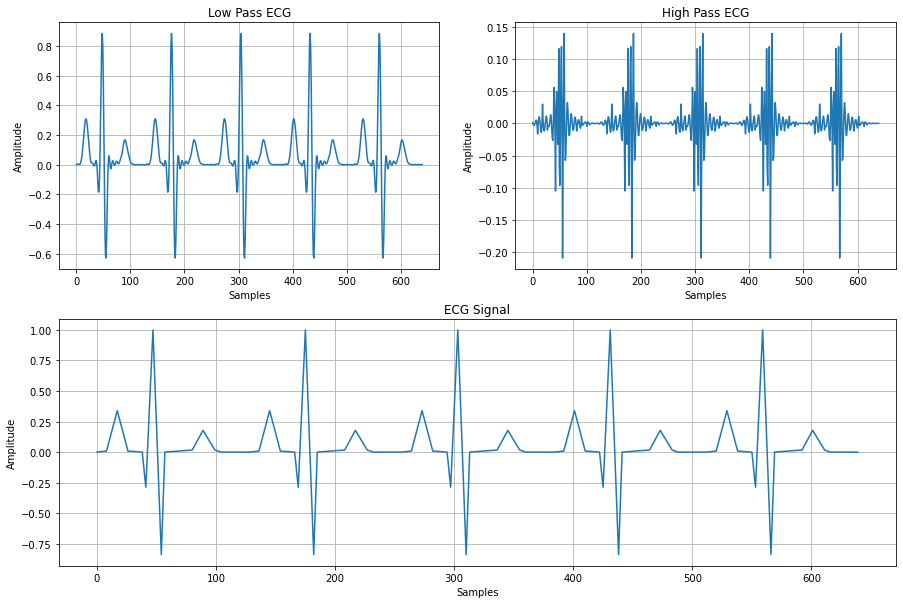

In [9]:
with open('convolve_spectral.pkl', 'rb') as file:
    low_pass_ecg_pkl, high_pass_ecg_pkl = pickle.load(file)
    
assert np.allclose(low_pass_ecg_pkl, low_pass_ecg, atol=0.01)
assert np.allclose(high_pass_ecg_pkl, high_pass_ecg, atol=0.01)

plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(low_pass_ecg)
plt.title('Low Pass ECG')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(2,2,2)
plt.plot(high_pass_ecg)
plt.title('High Pass ECG')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(2,1,2)
plt.plot(ecg)
plt.title('ECG Signal')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude');

## Why Does Spectral Inversion Work?

Spectral inversion is based on the following idea. A low-pass filter generates a signal with the high frequencies removed. Hence, if you subtract this signal from the original one, you have exactly the high frequencies. This means that you can implement a high-pass filter in two steps. First, you compute

$$x_\mathrm{lpf}[n]=x[n]*h_\mathrm{lpf}[n]$$

where $x[n]$ is the original signal, $h_{lpf}[n]$ is the low-pass filter, and $x_{lpf}[n]$ is the low-pass-filtered signal. The asterisk represents convolution. Second, you compute

$$x_\mathrm{hpf}[n]=x[n]-x_\mathrm{lpf}[n]$$

where $x_{hpf}[n]$ is the high-pass-filtered signal.

The alternative is to adapt the filter through spectral inversion. To show that spectral inversion has exactly the same result, first note that $x[n]=x[n]*\delta[n]$, where $\delta[n]$ is a simple impulse, as defined in Impulse Response. You can then write

$$x_\mathrm{hpf}[n]=x[n]-x_\mathrm{lpf}[n]=x[n]*\delta[n]-x[n]*h_\mathrm{lpf}[n]=x[n]*(\delta[n]-h_\mathrm{lpf}[n])$$

where the last step follows from the distributive property of convolution. This means that the required high-pass filter is

$$h_\mathrm{hpf}[n]=\delta[n]-h_\mathrm{lpf}[n]$$

which is exactly the procedure that I’ve described before.

#### Reference:
* https://tomroelandts.com/articles/how-to-create-a-simple-high-pass-filter